In [1]:
import pandas as pd
import numpy as np
import mplfinance as mpf
from datetime import datetime, timedelta
import pandas_ta as ta
import os

# Import tdata package functionality
from packages.tdata.ingestion import get_rts_data, extract_tickers, get_figis, fetch_ohlcv_data
from packages.tdata.processing import calculate_indicators, process_file_with_indicators

# OHLCV Data Visualization Demo

This notebook demonstrates how to visualize OHLCV (Open, High, Low, Close, Volume) data and technical indicators using the tdata package. We'll cover:
1. Fetching market data
2. Calculating technical indicators
3. Visualizing various charts including:
   - Candlestick patterns with volume
   - Moving Averages (SMA)
   - Relative Strength Index (RSI)
   - MACD (Moving Average Convergence Divergence)
   - Bollinger Bands
   - ADX (Average Directional Index)
   - Stochastic Oscillator
   - On-Balance Volume (OBV)

# Loading Market Data

In this notebook, we'll demonstrate loading market data using the updated tdata package. The package now automatically handles:
1. Date conversion to pandas datetime format
2. Setting the original 'date' column as the index
3. Preserving datetime information in 'date_time' column for calculations
4. Basic data preprocessing and validation

The data will be structured with:
- DateTime index (from 'date' column) for time series operations
- `date_time` column preserved for calculations and indicators
- All standard OHLCV columns

This means you no longer need to manually convert dates or set index - these operations are handled internally by the `fetch_ohlcv_data` function.

In [ ]:
# Load environment variables from .env file
TOKEN = os.getenv("TINKOFF_TOKEN")

# Set the date range for data retrieval
end_date = pd.Timestamp("2024-12-31T12:00:00Z")
start_date = end_date - timedelta(days=30)

# Define the candle interval
interval = "1hour"  # Options: 1min, 5min, 15min, 1hour, 1day, etc.

# Get tickers and their FIGIs
tickers = extract_tickers()
ticker_figis = get_figis(tickers, TOKEN)

# Fetch OHLCV data and calculate indicators
df = fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN)

# Save df to a csv file
data_directory = os.path.join('app', 'data', 'data')
output_file = f"{data_directory}/test_ohlcv_data.csv"
if not df.empty:
    df.to_csv(output_file, index=True)  # Save with index to preserve the DatetimeIndex
    print(f"Data saved to {output_file}")


Data saved to /app/data/data/test_ohlcv_data.csv


In [17]:
data_directory = os.path.join('data', 'data')
output_file = f"{data_directory}/test_ohlcv_data.csv"

# Load the saved data with proper date parsing
df = pd.read_csv(output_file)
df['date'] = pd.to_datetime(df['date'])  # Convert date column to datetime
df.set_index('date', inplace=True)  # Set date as index
df.sort_index(inplace=True)  # Sort by date

# Now calculate indicators
df = calculate_indicators(df)

/app/packages/tdata/processing/indicators.py:75: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data['vwap'] = ta.vwap(data['high'], data['low'], data['close'], data['volume'])
/app/packages/tdata/processing/indicators.py:75: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data['vwap'] = ta.vwap(data['high'], data['low'], data['close'], data['volume'])
/app/packages/tdata/processing/indicators.py:75: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data['vwap'] = ta.vwap(data['high'], data['low'], data['close'], data['volume'])
/app/packages/tdata/processing/indicators.py:75: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data['vwap'] = ta.vwap(data['high'], data['low'], data['close'], data['volume'])
/app/packages/tdata/processing/indicators.py:75: UserWarning: Converting to PeriodArray/Index representa

In [18]:
df

,date,figi,date.1,open,high,low,close,volume,tic,day,...,bb_lower,bb_middle,bb_upper,vwap,adx,adx_positive,adx_negative,stoch_k,stoch_d,obv
0,2024-12-01 12:00:00+00:00,BBG004731032,2024-12-01 12:00:00+00:00,6866.00,6878.50,6857.00,6859.00,240,LKOH,6,...,NaN,NaN,NaN,6864.833333,NaN,NaN,NaN,NaN,NaN,240.0
1,2024-12-01 13:00:00+00:00,BBG004731032,2024-12-01 13:00:00+00:00,6860.00,6879.00,6858.00,6871.00,246,LKOH,6,...,NaN,NaN,NaN,6867.111111,NaN,NaN,NaN,NaN,NaN,486.0
2,2024-12-01 14:00:00+00:00,BBG004731032,2024-12-01 14:00:00+00:00,6860.50,6871.00,6860.00,6862.50,154,LKOH,6,...,NaN,NaN,NaN,6866.482813,NaN,NaN,NaN,NaN,NaN,332.0
3,2024-12-01 15:00:00+00:00,BBG004731032,2024-12-01 15:00:00+00:00,6871.00,6872.00,6860.00,6871.50,171,LKOH,6,...,NaN,NaN,NaN,6866.767571,NaN,NaN,NaN,NaN,NaN,503.0
4,2024-12-01 16:00:00+00:00,BBG004731032,2024-12-01 16:00:00+00:00,6870.00,6877.00,6860.00,6876.50,155,LKOH,6,...,NaN,NaN,NaN,6867.473430,NaN,NaN,NaN,NaN,NaN,658.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22794,2024-12-30 16:00:00+00:00,BBG000BSJK37,2024-12-30 16:00:00+00:00,22.52,22.67,22.50,22.63,2953845,T,0,...,22.574513,22.8830,23.191487,22.559753,22.152193,18.638393,32.523526,14.754453,12.704668,-9069681.0
22795,2024-12-30 17:00:00+00:00,BBG000BSJK37,2024-12-30 17:00:00+00:00,22.64,22.73,22.63,22.65,3215195,T,0,...,22.545204,22.8675,23.189796,22.588100,21.894495,21.046573,30.629922,25.389373,16.968658,-5854486.0
22796,2024-12-30 18:00:00+00:00,BBG000BSJK37,2024-12-30 18:00:00+00:00,22.65,22.71,22.64,22.71,1665977,T,0,...,22.528657,22.8550,23.181343,22.599688,21.655209,20.161660,29.342072,35.449735,25.197854,-4188509.0
22797,2024-12-30 19:00:00+00:00,BBG000BSJK37,2024-12-30 19:00:00+00:00,22.71,22.73,22.66,22.72,2198091,T,0,...,22.515154,22.8435,23.171846,22.613607,21.217346,20.525957,28.071024,40.211640,33.683583,-1990418.0


## Visualizing Technical Indicators

Let's create various plots to analyze the price action and technical indicators:

# Working with Dates in the Dataset

The DataFrame from tdata package always has:
- A proper DatetimeIndex (already sorted)
- No separate date columns needed

For filtering and date operations:
1. Use pd.Timestamp for creating dates
2. Compare directly with the index
3. No conversions needed - it just works!

In [20]:
# Determine the end_date by selecting maximum date in the DataFrame
end_date = pd.to_datetime(df.index.max())  # Convert to datetime explicitly

# Check index type
print("Index type:", type(df.index))
print("Index dtype:", df.index.dtype)

# Filter by date range
df['2024-01-01':'2024-01-31']

# Get data after a specific date
df[df.index > '2024-01-01']

# Get last N days of data
df[df.index >= (df.index.max() - timedelta(days=30))]

Index type: <class 'pandas.core.indexes.range.RangeIndex'>
Index dtype: int64


TypeError: cannot do slice indexing on RangeIndex with these indexers [2024-01-01] of type str

In [ ]:
# Select ticker to visualize
ticker = "NVTK"
chart_df = df[df['tic'] == ticker]

# The index is already DatetimeIndex, so we can filter directly
filter_date = pd.Timestamp(end_date - timedelta(days=7))
chart_df = chart_df[chart_df.index >= filter_date]

# Create plot addons for different indicators
bb_upper_plot = mpf.make_addplot(chart_df['bb_upper'], color='green', linestyle='dashdot')
bb_lower_plot = mpf.make_addplot(chart_df['bb_lower'], color='red', linestyle='dashdot')
bb_middle_plot = mpf.make_addplot(chart_df['bb_middle'], color='blue')

rsi_plot = mpf.make_addplot(chart_df['rsi'], panel=1, color='purple', ylabel='RSI')

macd_line = mpf.make_addplot(chart_df['macd_line'], panel=2, color='blue', ylabel='MACD')
macd_signal = mpf.make_addplot(chart_df['macd_signal'], panel=2, color='orange')
macd_histogram = mpf.make_addplot(chart_df['macd_histogram'], type='bar', panel=2, 
                                 color=['green' if v >= 0 else 'red' for v in chart_df['macd_histogram']])

sma_12_plot = mpf.make_addplot(chart_df['sma_12'], color='blue', width=1.5)
sma_26_plot = mpf.make_addplot(chart_df['sma_26'], color='orange', width=1.5)
sma_50_plot = mpf.make_addplot(chart_df['sma_50'], color='green', width=1.5)
sma_100_plot = mpf.make_addplot(chart_df['sma_100'], color='red', width=1.5)

# 1. Plot candlestick chart with Bollinger Bands
mpf.plot(chart_df, type='candle', volume=False, 
         title=f"{ticker} - Candlestick Chart with Bollinger Bands",
         style='yahoo', 
         figsize=(30, 10),
         addplot=[bb_upper_plot, bb_middle_plot, bb_lower_plot])

# 2. Plot candlestick chart with RSI
mpf.plot(chart_df, type='candle', volume=False, 
         title=f"{ticker} - Candlestick Chart with RSI",
         style='yahoo', 
         figsize=(30, 10),
         addplot=[rsi_plot])

TypeError: '>=' not supported between instances of 'numpy.ndarray' and 'Timestamp'

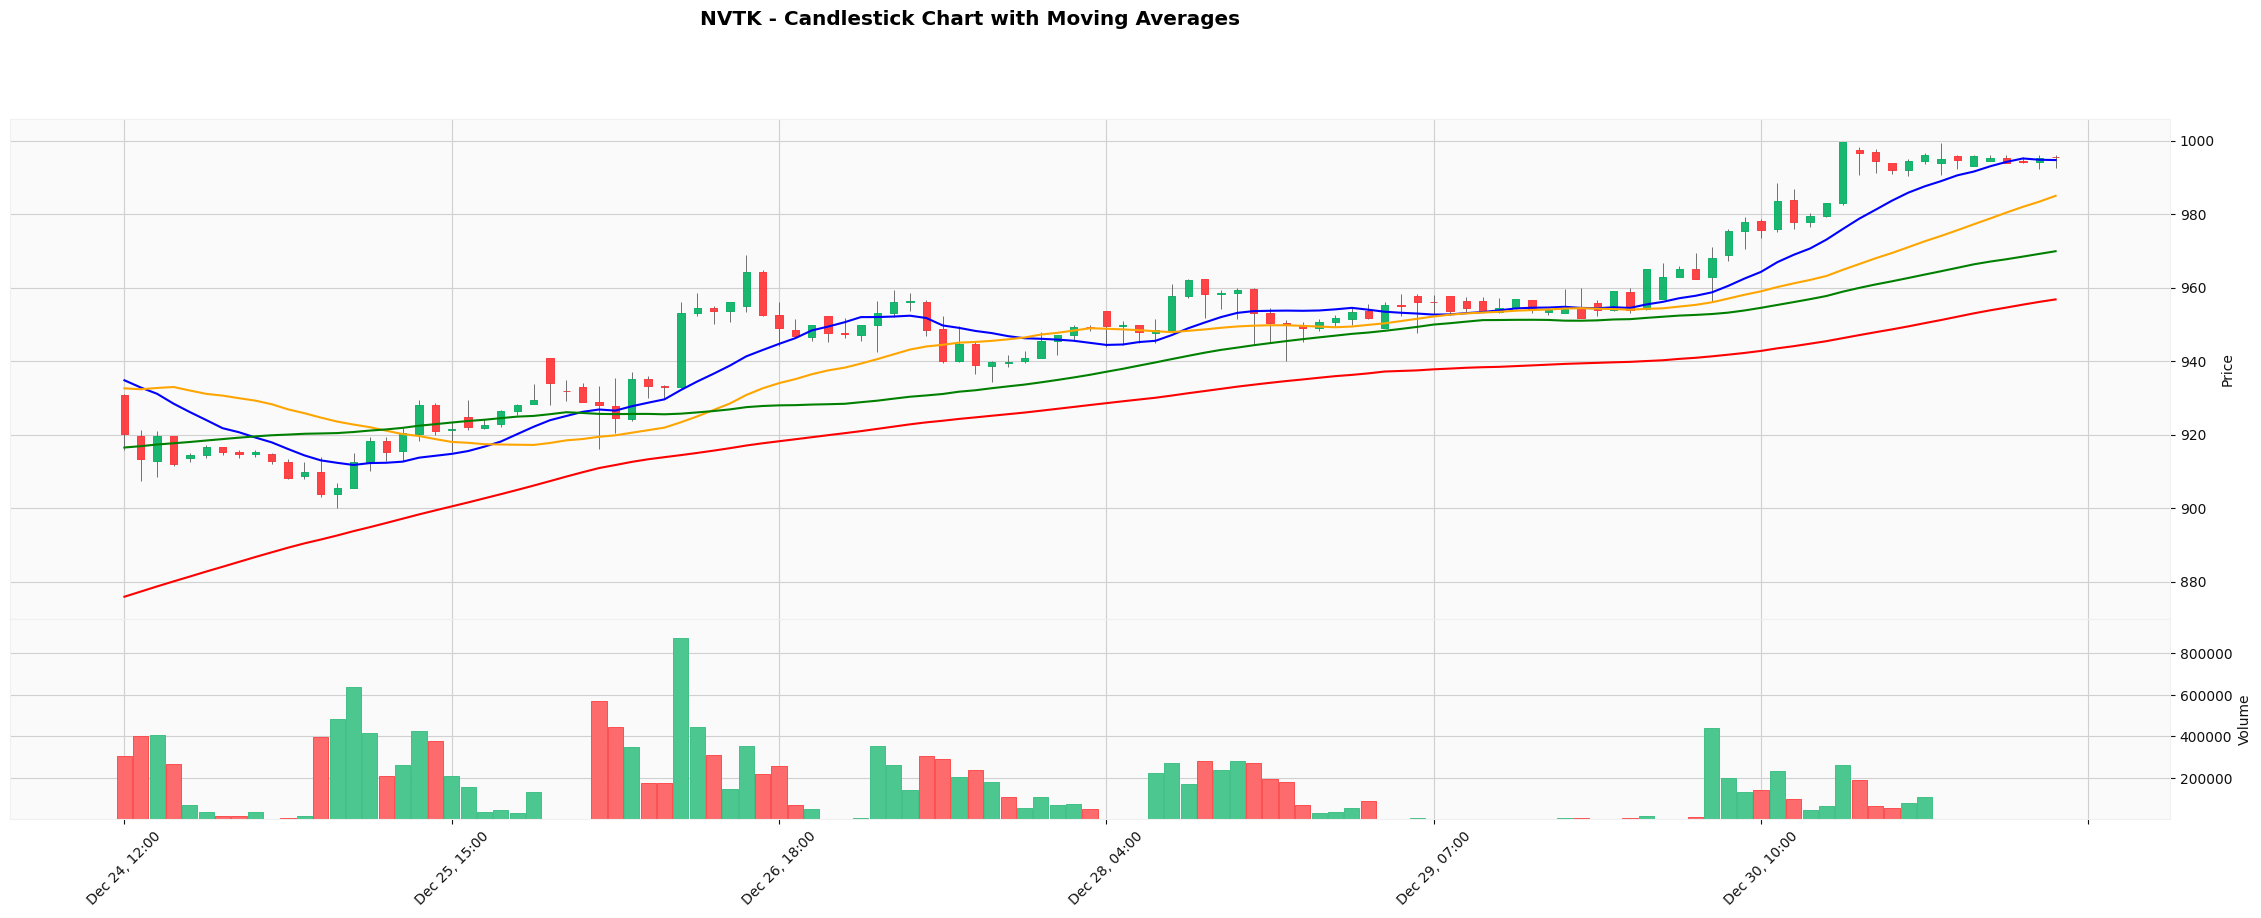

In [9]:
# 3. Plot candlestick chart with all SMAs
mpf.plot(chart_df, type='candle', volume=True,
         title=f"{ticker} - Candlestick Chart with Moving Averages",
         style='yahoo',
         figsize=(30, 10),
         addplot=[sma_12_plot, sma_26_plot, sma_50_plot, sma_100_plot])

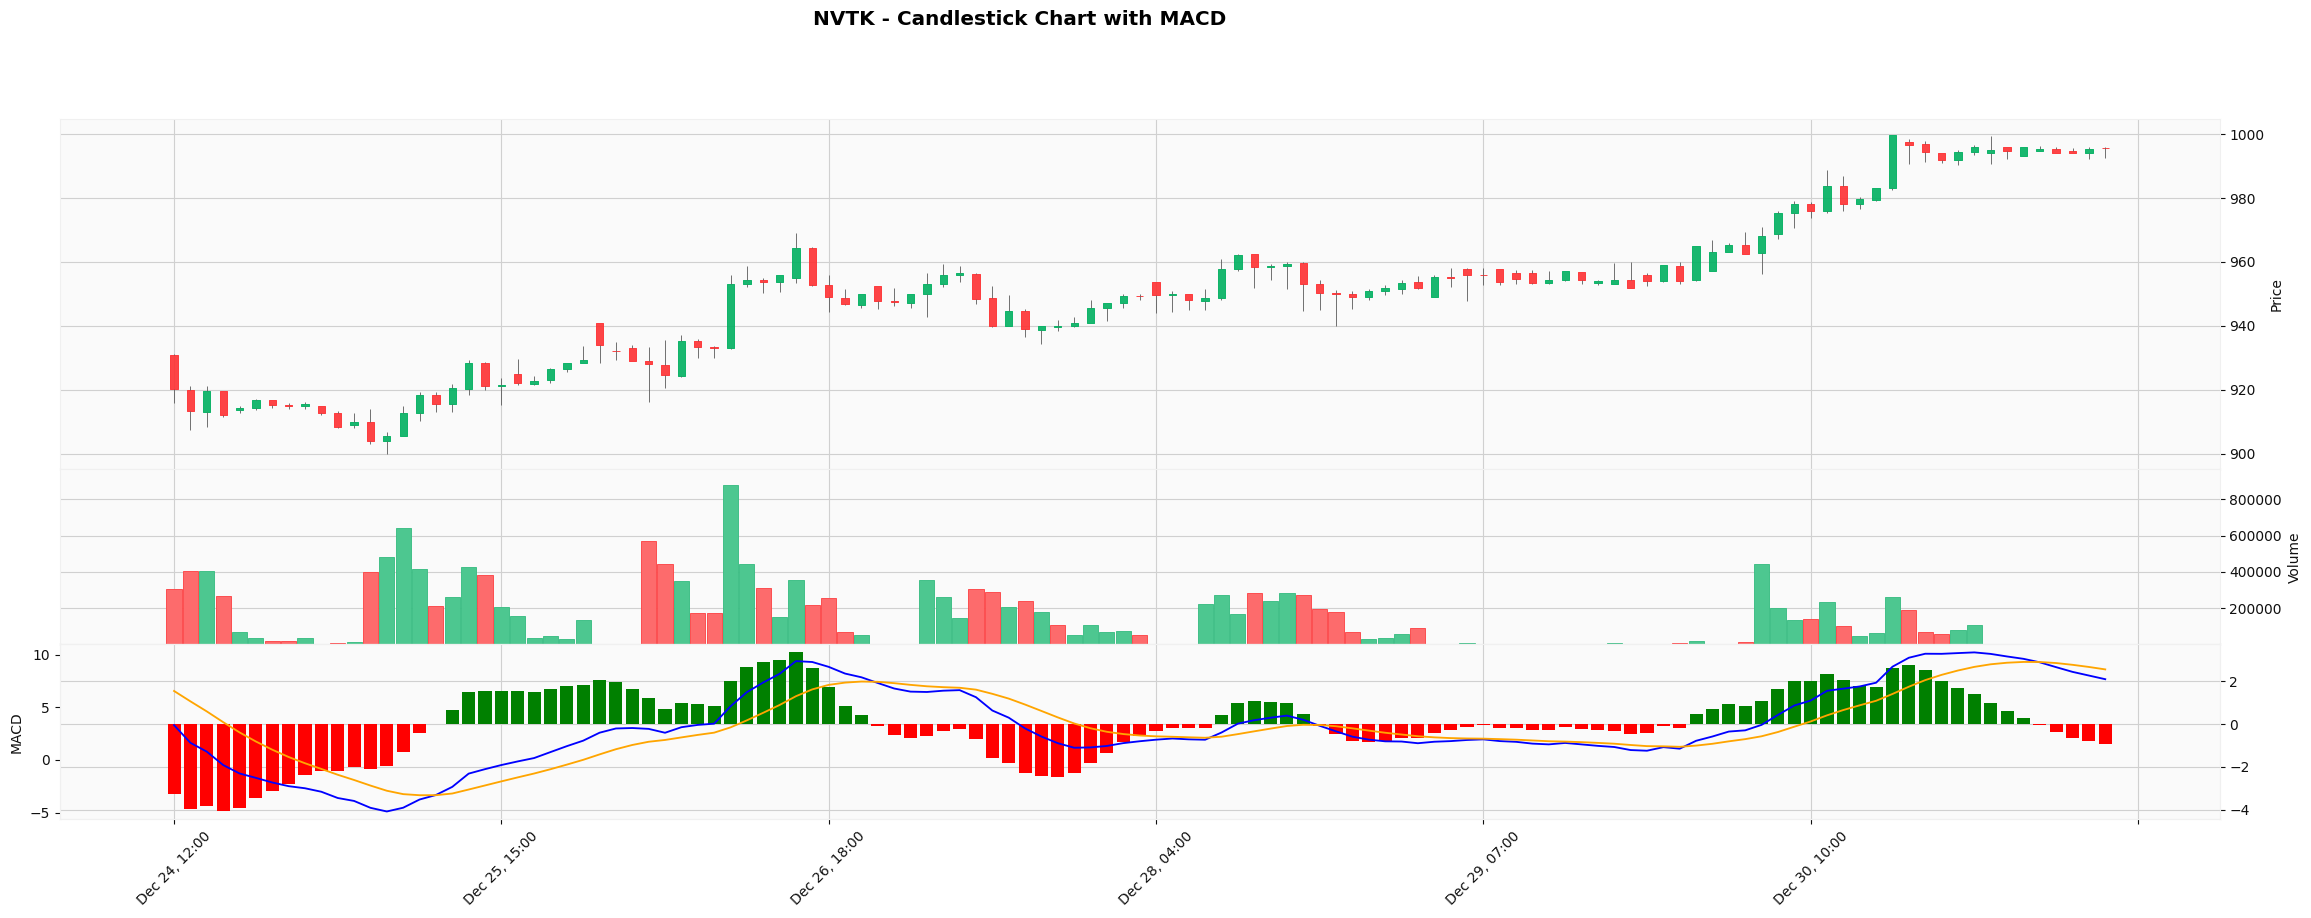

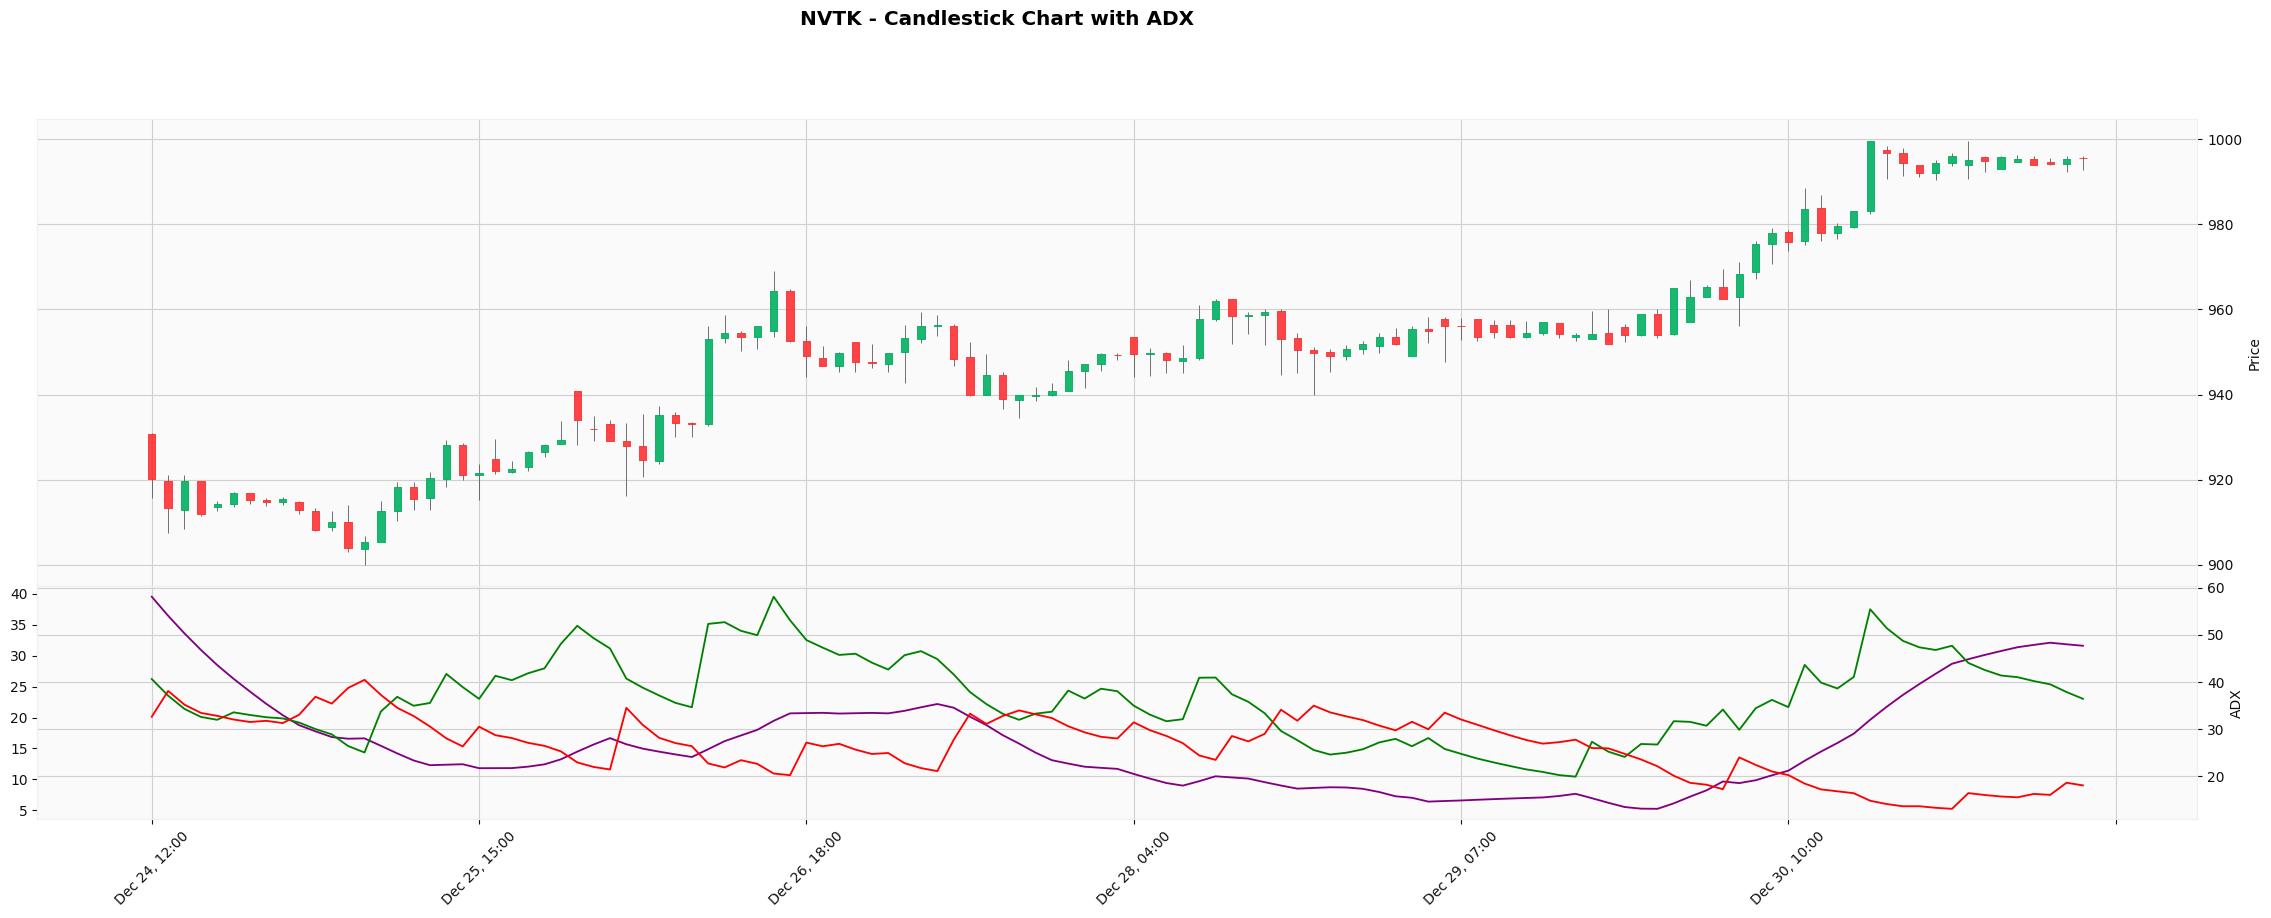

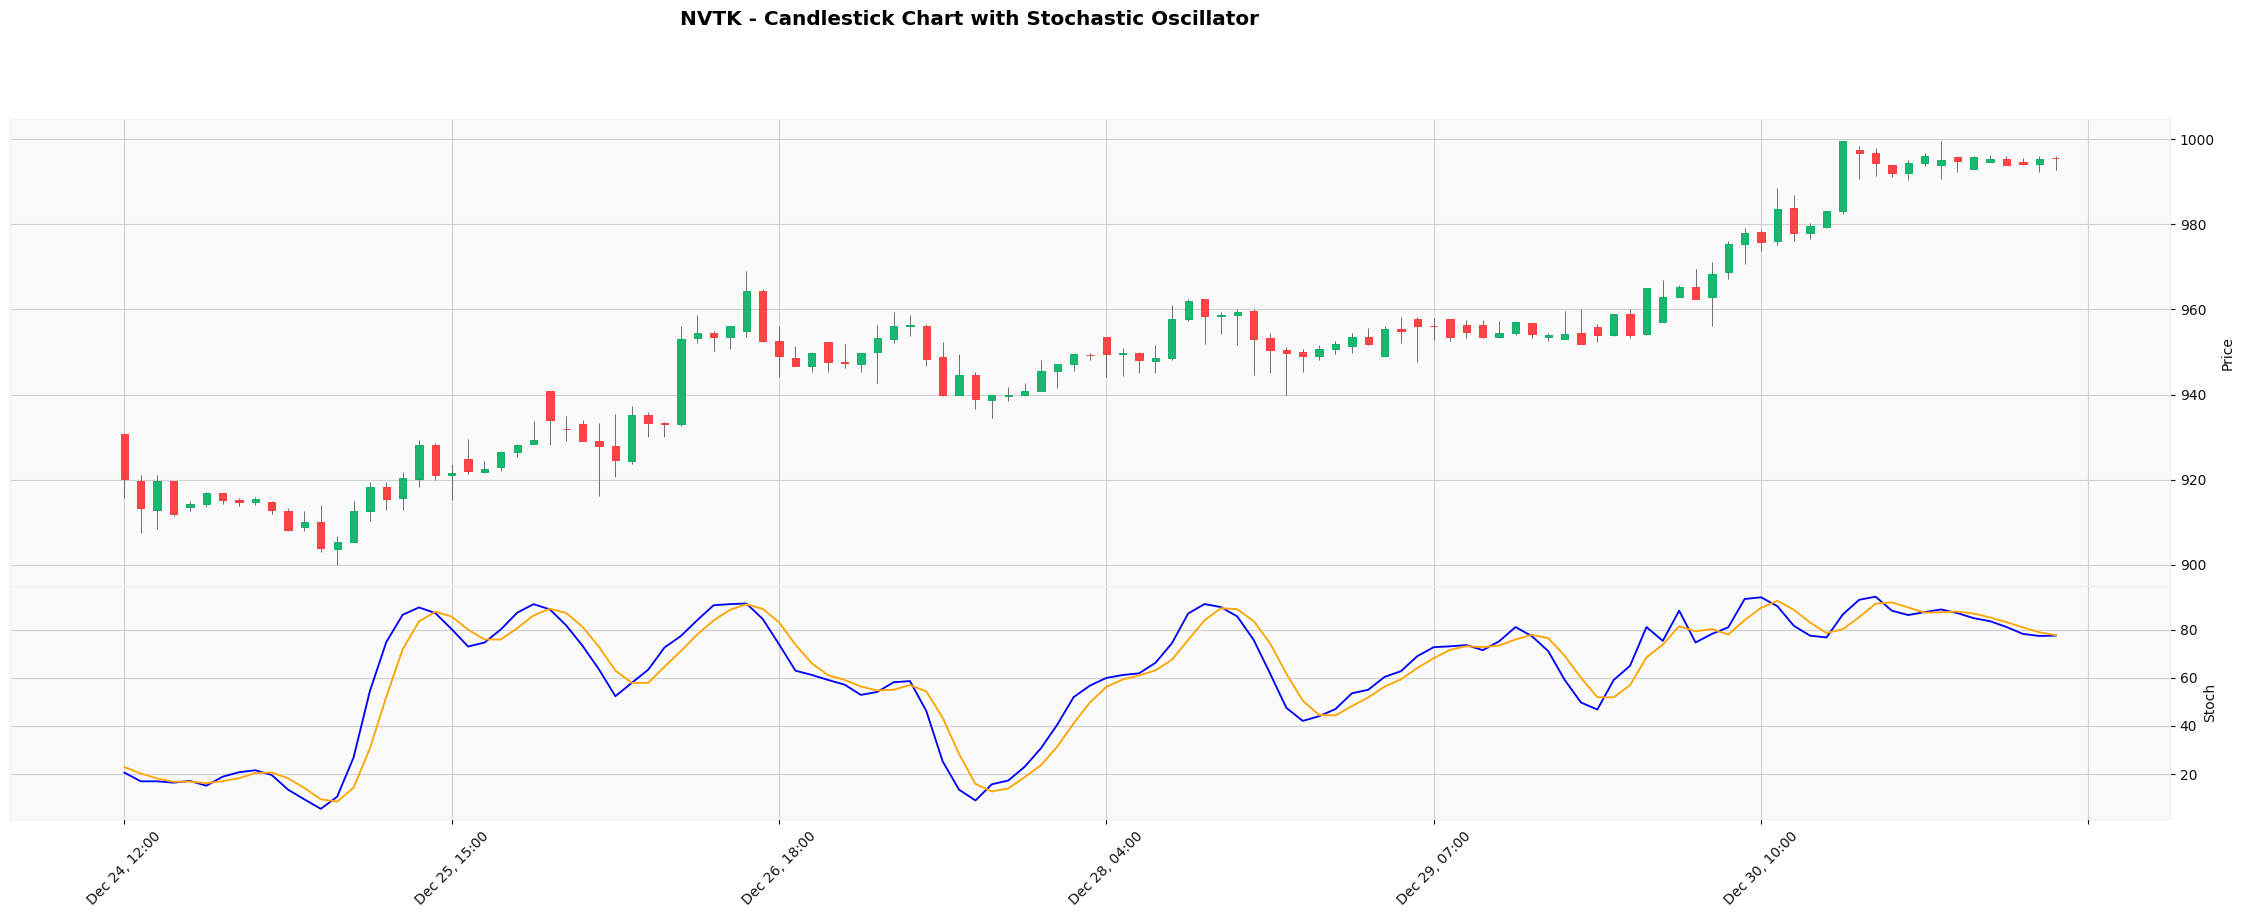

In [10]:
# 4. Plot candlestick chart with MACD
mpf.plot(chart_df, type='candle', volume=True,
         title=f"{ticker} - Candlestick Chart with MACD",
         style='yahoo',
         figsize=(30, 10),
         addplot=[macd_histogram, macd_line, macd_signal],
         panel_ratios=(2, 1))

# Create plots for ADX and Stochastic
adx_plot = mpf.make_addplot(chart_df['adx'], panel=1, color='purple', ylabel='ADX')
adx_pos_plot = mpf.make_addplot(chart_df['adx_positive'], panel=1, color='green')
adx_neg_plot = mpf.make_addplot(chart_df['adx_negative'], panel=1, color='red')

stoch_k_plot = mpf.make_addplot(chart_df['stoch_k'], panel=1, color='blue', ylabel='Stoch')
stoch_d_plot = mpf.make_addplot(chart_df['stoch_d'], panel=1, color='orange')

# 5. Plot candlestick chart with ADX
# ADX > 25 indicates a strong trend (either up or down)
mpf.plot(chart_df, type='candle', volume=False,
         title=f"{ticker} - Candlestick Chart with ADX",
         style='yahoo',
         figsize=(30, 10),
         addplot=[adx_plot, adx_pos_plot, adx_neg_plot],
         panel_ratios=(2, 1))

# 6. Plot candlestick chart with Stochastic Oscillator
# Values over 80 indicate overbought, under 20 indicate oversold
mpf.plot(chart_df, type='candle', volume=False,
         title=f"{ticker} - Candlestick Chart with Stochastic Oscillator",
         style='yahoo',
         figsize=(30, 10),
         addplot=[stoch_k_plot, stoch_d_plot],
         panel_ratios=(2, 1))

## Understanding the Technical Indicators

1. **Bollinger Bands**
   - Three lines: Upper, Middle (20-day SMA), and Lower bands
   - Upper/Lower bands are 2 standard deviations from the middle band
   - Price touching the upper band might indicate overbought conditions
   - Price touching the lower band might indicate oversold conditions

2. **Relative Strength Index (RSI)**
   - Momentum oscillator measuring speed and change of price movements
   - Values range from 0 to 100
   - Above 70 typically indicates overbought conditions
   - Below 30 typically indicates oversold conditions

3. **Moving Averages (SMA)**
   - SMA 12, 26, 50, and 100 periods shown
   - Shorter periods (12, 26) for short-term trends
   - Longer periods (50, 100) for long-term trends
   - Crossovers can signal trend changes

4. **MACD (Moving Average Convergence Divergence)**
   - Blue line: MACD line (12-day EMA minus 26-day EMA)
   - Orange line: Signal line (9-day EMA of MACD)
   - Histogram: Difference between MACD and Signal lines
   - Crossovers and divergences can signal trend changes

5. **ADX (Average Directional Index)**
   - Measures trend strength regardless of direction
   - ADX > 25 indicates a strong trend
   - Green line (+DI) shows uptrend strength
   - Red line (-DI) shows downtrend strength

6. **Stochastic Oscillator**
   - Shows momentum by comparing closing price to price range
   - Blue line (K): Fast stochastic
   - Orange line (D): Slow stochastic
   - Above 80 indicates overbought
   - Below 20 indicates oversold